In [1]:

# Install required packages in Colab
!pip install geopandas rasterio shapely scikit-learn matplotlib


In [2]:
import geopandas as gpd
import rasterio
import rasterio.mask
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from shapely.geometry import Point


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from google.colab import files

# Upload file from your computer
uploaded = files.upload()

# After running this, pick your .csv file from your computer
# Example: "simulated_drought_climate_data.csv"


Saving HV_subsoilpH.csv to HV_subsoilpH (1).csv


In [5]:
# Example: load CSV with columns id, x, y, pH60_100cm
df = pd.read_csv("HV_subsoilpH.csv")

# Round pH values
df["pH60_100cm"] = df["pH60_100cm"].round(2)

# Convert to GeoDataFrame
geometry = [Point(xy) for xy in zip(df.x, df.y)]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

In [6]:
import glob

# Load raster files from the GeoTIFF_Collection folder in Google Drive
rasters = glob.glob("/content/drive/MyDrive/GeoTIFF_Collection/hunterCovariates_sub*.tif")

# Stack rasters into a dictionary
raster_layers = {}
for r in rasters:
    name = r.split("/")[-1].replace(".tif","")
    raster_layers[name] = rasterio.open(r)

In [7]:
def extract_raster_values(gdf, raster_layers):
    for name, src in raster_layers.items():
        coords = [(x,y) for x,y in zip(gdf.geometry.x, gdf.geometry.y)]
        values = [val[0] for val in src.sample(coords)]
        gdf[name] = values
    return gdf

DSM_data = extract_raster_values(gdf.copy(), raster_layers)
DSM_data = DSM_data.dropna()


# Train/Test

In [8]:
from sklearn.model_selection import train_test_split

X = DSM_data[["AACN","Landsat_Band1","Elevation","Hillshading",
              "Mid_Slope_Positon","MRVBF","NDVI","TWI"]]
y = DSM_data["pH60_100cm"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)


# Random Forest Model

In [9]:
rf = RandomForestRegressor(n_estimators=1000, random_state=123)
rf.fit(X_train, y_train)

print("Training R2:", rf.score(X_train, y_train))
print("Test R2:", rf.score(X_test, y_test))


Training R2: 0.879590594299771
Test R2: 0.22136703164306404


# Variable Importance Plot

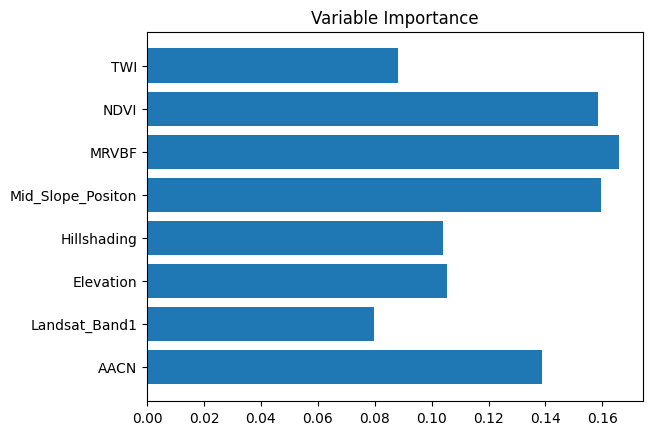

In [10]:
importances = rf.feature_importances_
plt.barh(X.columns, importances)
plt.title("Variable Importance")
plt.show()


# 9. Validation

In [11]:
# Internal validation
y_pred_train = rf.predict(X_train)
print("Train R2:", r2_score(y_train, y_pred_train))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_train)))

# External validation
y_pred_test = rf.predict(X_test)
print("Test R2:", r2_score(y_test, y_pred_test))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test)))


Train R2: 0.879590594299771
Train RMSE: 0.4591258919446402
Test R2: 0.22136703164306404
Test RMSE: 1.2247558352071128


# 10. Apply Model Spatially

In [18]:
import os
print(os.listdir('/content/drive/MyDrive/HV_soilPH'))

['hunterCovariates_sub_NDVI.tif', 'hunterCovariates_sub_TWI.tif', 'hunterCovariates_sub_Slope.tif', 'hunterCovariates_sub_Light_insolation.tif', 'hunterCovariates_sub_Landsat_Band1.tif', 'hunterCovariates_sub_MRVBF.tif', 'hunterCovariates_sub_Elevation.tif', 'hunterCovariates_sub_AACN.tif', 'hunterCovariates_sub_Mid_Slope_Positon.tif', 'hunterCovariates_sub_Terrain_Ruggedness_Index.tif', 'hunterCovariates_sub_Hillshading.tif', 'soilpH_60_100_RF.tif']


In [13]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# List files in your HV_soilPH folder
folder_path = '/content/drive/MyDrive/HV_soilPH'
print(os.listdir(folder_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['hunterCovariates_sub_NDVI.tif', 'hunterCovariates_sub_TWI.tif', 'hunterCovariates_sub_Slope.tif', 'hunterCovariates_sub_Light_insolation.tif', 'hunterCovariates_sub_Landsat_Band1.tif', 'hunterCovariates_sub_MRVBF.tif', 'hunterCovariates_sub_Elevation.tif', 'hunterCovariates_sub_AACN.tif', 'hunterCovariates_sub_Mid_Slope_Positon.tif', 'hunterCovariates_sub_Terrain_Ruggedness_Index.tif', 'hunterCovariates_sub_Hillshading.tif']


In [19]:
import rasterio
import numpy as np

# Collect all tif files
tif_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]
print("Found rasters:", tif_files)

# Read and stack
arrays = []
for f in tif_files:
    with rasterio.open(f) as src:
        arrays.append(src.read(1))   # read first band

stack = np.stack(arrays, axis=-1)
print("Stack shape:", stack.shape)


Found rasters: ['/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_NDVI.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_TWI.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Slope.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Light_insolation.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Landsat_Band1.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_MRVBF.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Elevation.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_AACN.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Mid_Slope_Positon.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Terrain_Ruggedness_Index.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Hillshading.tif', '/content/drive/MyDrive/HV_soilPH/soilpH_60_100_RF.tif']
Stack shape: (249, 210, 12)


Found rasters: ['/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_NDVI.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_TWI.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Slope.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Light_insolation.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Landsat_Band1.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_MRVBF.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Elevation.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_AACN.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Mid_Slope_Positon.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Terrain_Ruggedness_Index.tif', '/content/drive/MyDrive/HV_soilPH/hunterCovariates_sub_Hillshading.tif', '/content/drive/MyDrive/HV_soilPH/soilpH_60_100_RF.tif']
Stack for prediction shape: (249, 210, 8)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


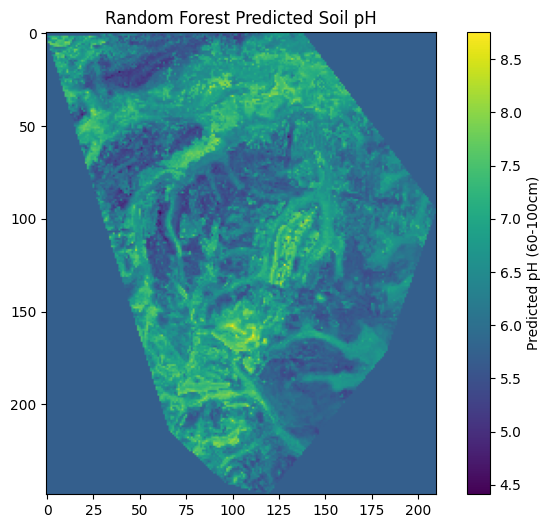

In [20]:
import os, rasterio
import numpy as np
import matplotlib.pyplot as plt

# Path to your folder in Drive
folder_path = '/content/drive/MyDrive/HV_soilPH'

# Collect all tif files
tif_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]
print("Found rasters:", tif_files)

# Define the order of features the model expects
training_features_order = ["AACN","Landsat_Band1","Elevation","Hillshading",
                           "Mid_Slope_Positon","MRVBF","NDVI","TWI"]

# Create a mapping from feature name to its original index in tif_files
feature_to_index = {}
for i, f in enumerate(tif_files):
    # Extract the base name (e.g., 'NDVI' from 'hunterCovariates_sub_NDVI.tif')
    base_name = f.split('/')[-1].replace('hunterCovariates_sub_', '').replace('.tif', '')
    feature_to_index[base_name] = i

# Get the indices of the required features in the correct order
ordered_indices = [feature_to_index[feat] for feat in training_features_order]

# Read and stack rasters, then reorder to match training features
arrays = []
srcs_all = [] # Keep all source metadata for the output raster if needed
for f in tif_files:
    src = rasterio.open(f)
    srcs_all.append(src)
    arrays.append(src.read(1))   # read first band

# Stack all arrays first
full_stack = np.stack(arrays, axis=-1)

# Select and reorder bands to match the training features
stack_for_prediction = full_stack[:, :, ordered_indices]

rows, cols, bands_for_pred = stack_for_prediction.shape
print("Stack for prediction shape:", stack_for_prediction.shape)

# Flatten for prediction
flat = stack_for_prediction.reshape(rows*cols, bands_for_pred)

# Predict soil pH
preds = rf.predict(flat)

# Reshape back to raster
pred_raster = preds.reshape(rows, cols)

# Save output raster back to Drive
# Use metadata from one of the original source files
out_meta = srcs_all[0].meta.copy()
out_meta.update({"count":1, "dtype":"float32"})

out_path = os.path.join(folder_path, "soilpH_60_100_RF.tif")
with rasterio.open(out_path, "w", **out_meta) as dest:
    dest.write(pred_raster.astype(np.float32), 1)

# Plot
plt.figure(figsize=(8,6))
plt.imshow(pred_raster, cmap="viridis")
plt.colorbar(label="Predicted pH (60-100cm)")
plt.title("Random Forest Predicted Soil pH")
plt.show()